In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from importlib import reload

import lspr

In [6]:
########################################
# -- Step 1 --
# Write the "xy_to_radec" function in "lspr.py", then run this cell to test it
########################################

reload(lspr)
lspr.main()


TEST 1: x, y = 0 0

Actual:   271.23586782
Expected: 271.23586782
Difference: 0.0

Actual:   14.692310024
Expected: 14.692310024
Difference: 0.0

TEST 2: x, y = 100 0

Actual:   271.03391682
Expected: 271.03391682
Difference: 0.0

Actual:   14.970271724
Expected: 14.970271724
Difference: 0.0

TEST 3: x, y = 57.3 201.1

Actual:   270.6119854806
Expected: 270.6119854806
Difference: 0.0

Actual:   14.482378968299999
Expected: 14.4823789683
Difference: -1.7763568394002505e-15



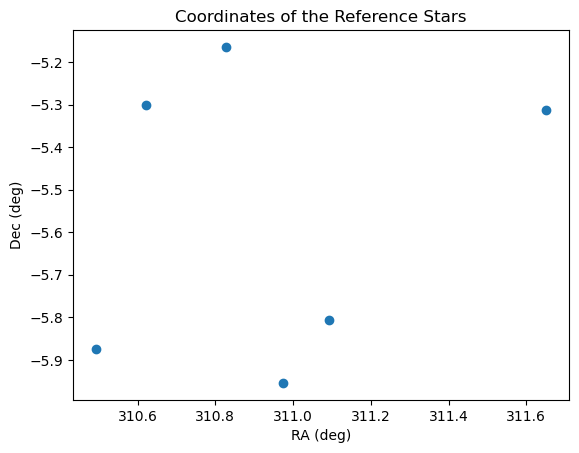

In [15]:
########################################
# -- Step 2 --
# Load the reference star catalog and plot their Dec vs. RA locations
########################################

# YOUR CODE HERE
ref_stars = pd.read_csv('reference_stars.csv')

RA_values = ref_stars["ra_deg"]
Dec_values = ref_stars["dec_deg"]

plt.scatter(RA_values, Dec_values)

# Add a title and axis labels
plt.title('Coordinates of the Reference Stars')
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')

# Display the plot! Prevents further changes
plt.show()


In [38]:
########################################
# -- Step 3 --
# Compute the plate solution coefficients
# (You may want to use multiple cells to spread out your work)
########################################

# YOUR CODE HERE
n = len(ref_stars)
x_ref = ref_stars["x_pix"] #correct
y_ref = ref_stars["y_pix"] #correct
ra_ref = ref_stars["ra_deg"]
dec_ref = ref_stars["dec_deg"]

xy_matrix = np.array([
    [n,  np.sum(x_ref),  np.sum(y_ref)],
    [np.sum(x_ref),  np.sum(x_ref**2),  np.sum(x_ref*y_ref)],
    [np.sum(y_ref),  np.sum(x_ref*y_ref),  np.sum(y_ref**2)]
])
#print(xy_matrix)
ra_lhs = np.array([
    [np.sum(ra_ref)],
    [np.sum(ra_ref*x_ref)],
    [np.sum(ra_ref*y_ref)] 
])

dec_lhs = np.array([
    [np.sum(dec_ref)],
    [np.sum(dec_ref*x_ref)],
    [np.sum(dec_ref*y_ref)]
])
#print(dec_lhs)

b1, a11, a12 = np.linalg.solve(xy_matrix, ra_lhs)
b2, a21, a22 = np.linalg.solve(xy_matrix, dec_lhs)
print(b1, a11, a12)
print(b2, a21, a22)


[[  1865.66079167]
 [105068.3357891 ]
 [ 42998.44910278]]
[313.66771434] [-0.04845397] [0.00021625]
[-4.45897726] [-0.00034355] [-0.04731988]


### Response 1 - Answer in your Jupyter notebook

1. RA = 313.67 Dec = -4.46
2. As x increases, RA and Dec decrease. RA decreases the greatest.
3. As y increases, RA increase and Dec decreases.
4. Negative y is closest to North.

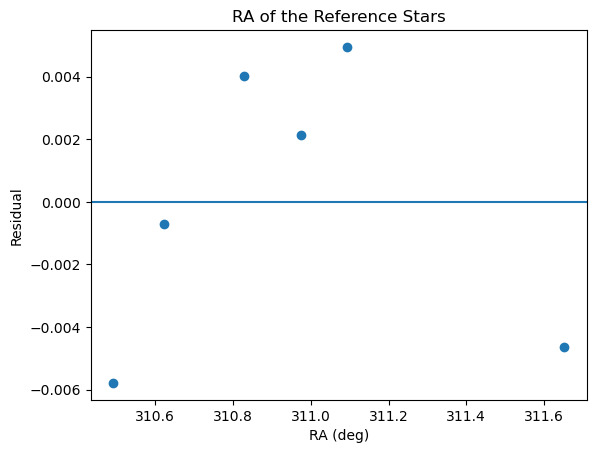

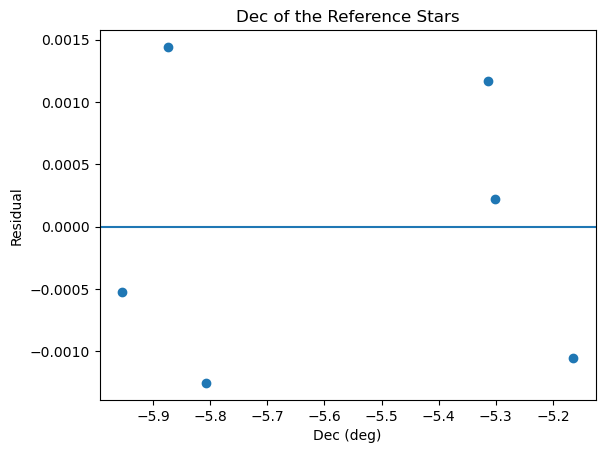

In [66]:
########################################
# -- Step 4 --
# Compute the RA & Dec value of each star using your plate solve, then plot the residuals
########################################

# YOUR CODE HERE
ra_est, dec_est = lspr.xy_to_radec(x_ref, y_ref, b1, a11, a12, b2, a21, a22)

plt.scatter(ra_ref, (ra_est - ra_ref))

plt.title('RA of the Reference Stars')
plt.xlabel('RA (deg)')
plt.ylabel('Residual')
plt.axhline(0)

plt.show()

plt.scatter(dec_ref, (dec_est - dec_ref))

plt.title('Dec of the Reference Stars')
plt.xlabel('Dec (deg)')
plt.ylabel('Residual')

plt.axhline(0)

plt.show()


### Response 2 - Answer in your Jupyter notebook

1. That the plate solution was always overestimating the RA.
2. It would indicate that the plate is incorrect.

In [67]:
########################################
# -- Step 5 --
# Determine your asteroid's coordinates (x=25, y=50)
########################################

# YOUR CODE HERE
lspr.xy_to_radec(50, 25, b1, a11, a12, b2, a21, a22)

(array([311.25042204]), array([-5.65915162]))